**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: Alejandro Rendón De Jesús
*   MATRÍCULA: A01664589

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

import warnings
from sklearn.neighbors import KernelDensity
warnings.filterwarnings('ignore')

# Estilo general de las gráficas
sns.set_theme(style = 'whitegrid')
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['figure.titleweight'] = 'bold'

COLOR_1 = '#2a78d6'    # azul
COLOR_2 = '#eb6834'    # naranja
COLOR_BAD = '#d03b3b'  # rojo (valores inválidos)

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [2]:
loan_df = pd.read_csv('personal_loan.csv')
loan_df.index = loan_df['ID'].values
loan_df = loan_df.drop(columns = 'ID')

# Número de registros del dataframe inicial (se usa más adelante)
n_inicial = loan_df.shape[0]

loan_df.head()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,25,1,49,91108,4,1.6,1.0,0,0,Yes,No,0,0
1,45,19,34,90089,3,1.5,1.0,0,No,Yes,No,No,0
2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2.0,0,0,0,0,No,0
4,35,8,45,91330,4,1.0,2.0,0,0,No,No,0,1


In [3]:
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


In [4]:
loan_df.dtypes.value_counts()

int64      6
object     5
float64    2
Name: count, dtype: int64

**Respuesta:**

El dataframe tiene 5037 registros y 13 columnas (sin contar `ID`, que ahora es el índice).

* **8 columnas son numéricas:** 6 de tipo `int64` (`Age`, `Experience`, `Income`, `ZIP Code`, `Family`, `Mortgage`) y 2 de tipo `float64` (`CCAvg`, `Education`).
* **5 columnas son de texto** (`object`): `Personal Loan`, `Securities Account`, `CD Account`, `Online` y `CreditCard`.

Las 5 columnas de texto deberían ser binarias (0/1) según la descripción, pero pandas las lee como texto porque mezclan formatos (`0`, `1`, `Yes`, `No`). Esto se corrige en el ejercicio 3. Ninguna columna tiene valores nulos.

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [5]:
loan_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,5037.0,45.411356,11.646805,23.0,35.0,45.0,55.0,144.0
Experience,5037.0,20.122494,11.461278,-3.0,10.0,20.0,30.0,43.0
Income,5037.0,73.898352,46.130504,8.0,39.0,64.0,98.0,224.0
ZIP Code,5037.0,93152.865595,2119.637960,9307.0,91911.0,93437.0,94608.0,96651.0
Family,5037.0,2.394679,1.151145,-3.0,1.0,2.0,3.0,4.0
CCAvg,5037.0,1.942404,1.755954,0.0,0.7,1.5,2.6,10.0
Education,5037.0,1.880941,0.843337,1.0,1.0,2.0,3.0,7.3
Mortgage,5037.0,56.500695,101.657580,0.0,0.0,0.0,101.0,635.0


Al revisar las estadísticas descriptivas se observan varios valores sospechosos:

* `Age`: el máximo es 144 años, lo cual no es plausible.
* `Experience`: el mínimo es -3. La experiencia laboral no puede ser negativa.
* `Family`: el mínimo es -3. El número de miembros de la familia no puede ser negativo.
* `ZIP Code`: el mínimo es 9307, un código de 4 dígitos, cuando el resto tiene 5 dígitos.
* `Education`: el máximo es 7.3, cuando la variable solo admite los niveles 1, 2 y 3.

`Income`, `CCAvg` y `Mortgage` tienen mínimos de 0 o mayores y máximos razonables, por lo que no se consideran inválidos.

**Edad mayor a 100 años**

In [6]:
loan_df_age_over_100 = loan_df[loan_df['Age'] > 100]
loan_df_age_over_100

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


In [7]:
loan_df = loan_df[loan_df['Age'] <= 100]

print(f'Registros eliminados por edad: {loan_df_age_over_100.shape[0]}')
print(f'Edad máxima después de la limpieza: {loan_df["Age"].max()}')

Registros eliminados por edad: 3
Edad máxima después de la limpieza: 67


**Justificación:** se eliminaron 3 registros con edades de 123, 130 y 144 años. No son plausibles: superan la edad máxima registrada para un ser humano y además el resto de los clientes tiene 67 años o menos. Lo más probable es que sean errores de captura.

**Valores nulos y valores negativos**

In [8]:
loan_df.isna().sum()

Age                   0
Experience            0
Income                0
ZIP Code              0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal Loan         0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
dtype: int64

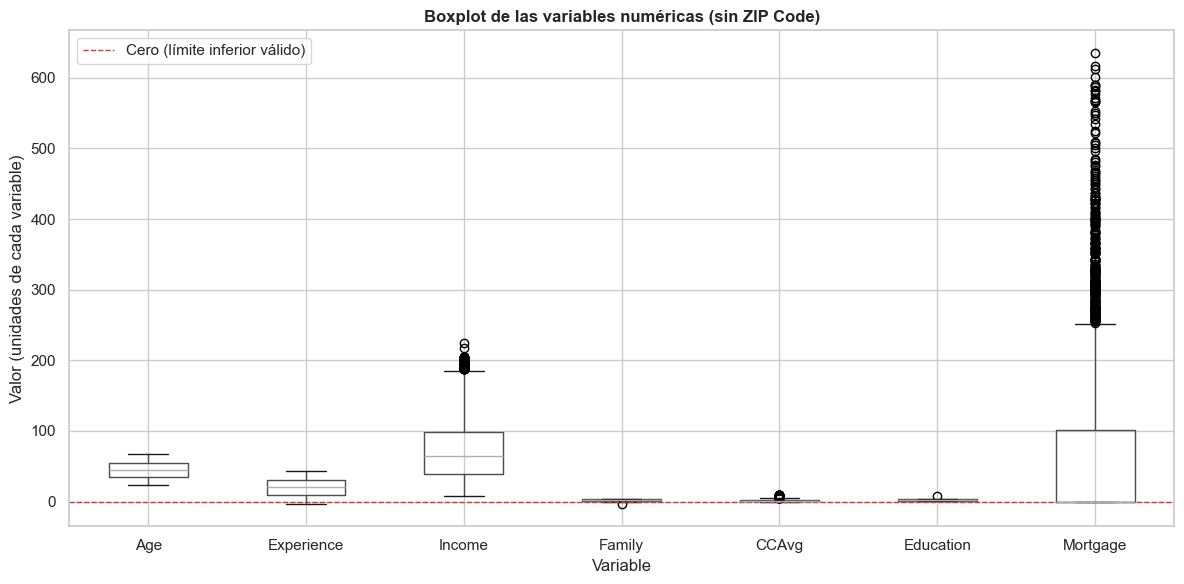

In [9]:
numCols_nocode = loan_df.select_dtypes(include = 'number').drop(columns = 'ZIP Code')

fig, ax = plt.subplots(figsize = (12, 6))
numCols_nocode.boxplot(ax = ax)

ax.axhline(0, color = COLOR_BAD, linestyle = '--', linewidth = 1, label = 'Cero (límite inferior válido)')
ax.set_title('Boxplot de las variables numéricas (sin ZIP Code)')
ax.set_xlabel('Variable')
ax.set_ylabel('Valor (unidades de cada variable)')
ax.legend(loc = 'upper left')

plt.tight_layout()
plt.show()

In [10]:
mask_negative_ = loan_df[numCols_nocode.columns[0]] < 0
for col in numCols_nocode.columns[1:]:
    mask_negative_ = mask_negative_ | (loan_df[col] < 0)

print('Valores negativos por columna:')
print((numCols_nocode < 0).sum())
print(f'\nRegistros con algún valor negativo: {loan_df[mask_negative_].shape[0]}')

Valores negativos por columna:
Age            0
Experience    53
Income         0
Family         2
CCAvg          0
Education      0
Mortgage       0
dtype: int64

Registros con algún valor negativo: 55


In [11]:
n_negativos = int(mask_negative_.sum())
loan_df = loan_df[~mask_negative_]

**Justificación:** no hay valores nulos. Sin embargo, 55 registros tienen valores negativos: 53 en `Experience` y 2 en `Family`. Ambas variables representan conteos (años trabajados y número de personas), por lo que un valor negativo no tiene sentido y se trata de un error de captura. Se eliminaron los 55 registros.

**Valores fuera de rango en `Education` y `ZIP Code`**

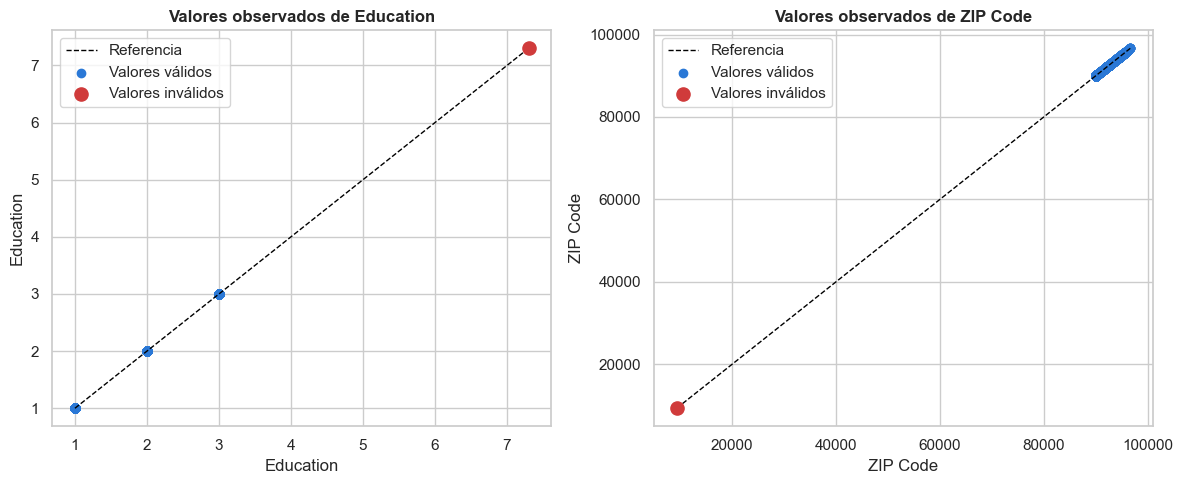

In [12]:
valid_education = loan_df['Education'].isin([1, 2, 3])
valid_zip = loan_df['ZIP Code'] > 20000

fig, ax = plt.subplots(figsize = (12, 5), nrows = 1, ncols = 2)
ax = ax.flatten()

for i, (col, valid) in enumerate(zip(['Education', 'ZIP Code'], [valid_education, valid_zip])):
    lims = [loan_df[col].min(), loan_df[col].max()]

    ax[i].plot(lims, lims, linestyle = '--', color = 'black', linewidth = 1, label = 'Referencia')
    ax[i].scatter(loan_df.loc[valid, col], loan_df.loc[valid, col], color = COLOR_1, label = 'Valores válidos')
    ax[i].scatter(loan_df.loc[~valid, col], loan_df.loc[~valid, col], color = COLOR_BAD, s = 90, zorder = 3, label = 'Valores inválidos')

    ax[i].set_title(f'Valores observados de {col}')
    ax[i].set_xlabel(col)
    ax[i].set_ylabel(col)
    ax[i].legend()

plt.tight_layout()
plt.show()

In [13]:
loan_df[~valid_education | ~valid_zip]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
347,25,0,43,94305,2,1.6,7.3,0,0,Yes,Yes,1,Yes
384,51,25,21,9307,4,0.6,3.0,0,No,0,0,1,Yes


In [14]:
n_fuera_rango = int((~valid_education | ~valid_zip).sum())

loan_df = loan_df[loan_df['ZIP Code'] > 20000]
loan_df = loan_df[loan_df['Education'] < 4].copy()

**Justificación:**

* `Education`: un registro tiene el valor 7.3. La variable es ordinal y solo admite 1 (graduado), 2 (universitario) y 3 (posgrado), así que 7.3 no corresponde a ninguna categoría.
* `ZIP Code`: un registro tiene el código 9307, de solo 4 dígitos. Los códigos postales de Estados Unidos tienen 5 dígitos y todos los demás registros están entre 90000 y 96651 (California), por lo que el valor está incompleto o mal capturado.

Se eliminaron ambos registros.

In [15]:
n_eliminados = n_inicial - loan_df.shape[0]

print(f'Registros iniciales:   {n_inicial}')
print(f'  Edad > 100 años:     {loan_df_age_over_100.shape[0]}')
print(f'  Valores negativos:   {n_negativos}')
print(f'  Fuera de rango:      {n_fuera_rango}')
print(f'Registros eliminados:  {n_eliminados} ({100 * n_eliminados / n_inicial:.2f}% del total inicial)')
print(f'Registros restantes:   {loan_df.shape[0]}')

Registros iniciales:   5037
  Edad > 100 años:     3
  Valores negativos:   55
  Fuera de rango:      2
Registros eliminados:  60 (1.19% del total inicial)
Registros restantes:   4977


**Respuesta:**

En este ejercicio se eliminaron **60 registros**, que representan el **1.19%** de los 5037 registros iniciales. Quedan 4977 registros.

| Acción | Registros eliminados |
|---|---|
| Edad mayor a 100 años | 3 |
| Valores negativos en `Experience` (53) y `Family` (2) | 55 |
| `Education` fuera de las categorías válidas | 1 |
| `ZIP Code` de 4 dígitos | 1 |
| **Total** | **60** |

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [16]:
loan_df.describe(include = 'object').T

,count,unique,top,freq
Personal Loan,4977,4,0,3475
Securities Account,4977,4,No,2693
CD Account,4977,4,No,2462
Online,4977,4,Yes,1700
CreditCard,4977,4,0,2628


In [17]:
catCols = loan_df.columns[(loan_df.dtypes == object).values]

for col in catCols:
    print(loan_df[col].value_counts().to_string())
    print()

Personal Loan
0      3475
No     1017
Yes     368
1       117

Securities Account
No     2693
0      1765
Yes     390
1       129

CD Account
No     2462
0      2212
1       163
Yes     140

Online
Yes    1700
No     1628
1      1275
0       374

CreditCard
0      2628
Yes     907
No      885
1       557



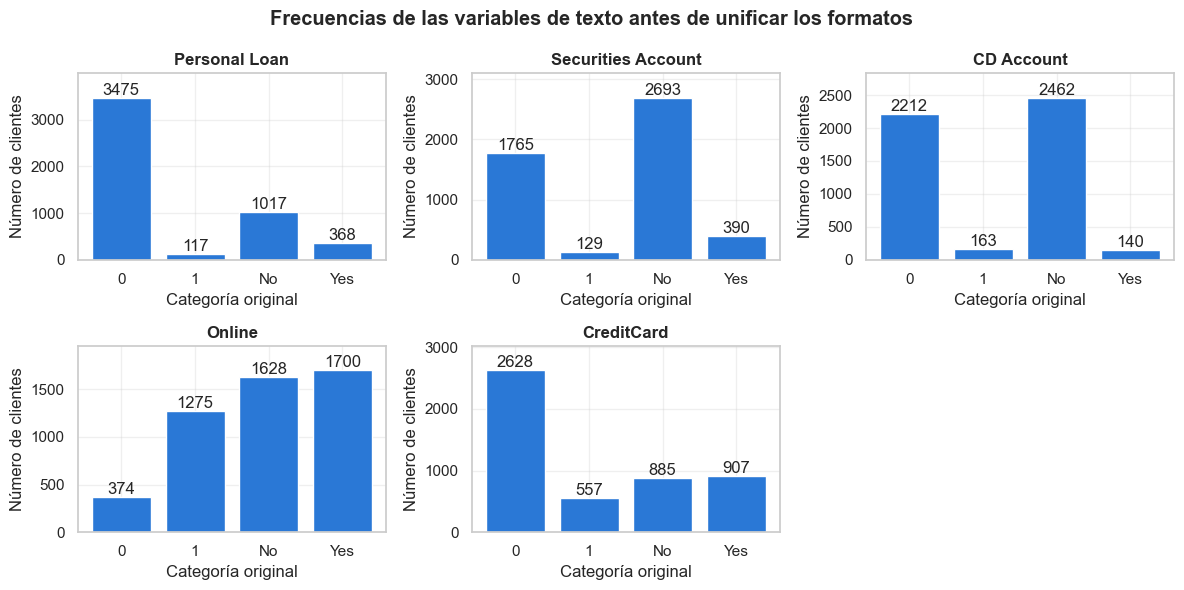

In [18]:
fig, ax = plt.subplots(figsize = (12, 6), nrows = 2, ncols = 3)
ax = ax.flatten()

for i, col in enumerate(catCols):
    counts_i = loan_df[col].value_counts().sort_index()
    bars = ax[i].bar(counts_i.index, counts_i.values, color = COLOR_1)
    ax[i].grid(alpha = 0.3)
    ax[i].set_axisbelow(True)

    ax[i].set_title(col)
    ax[i].set_xlabel('Categoría original')
    ax[i].set_ylabel('Número de clientes')
    ax[i].set_ylim([0, counts_i.values.max() * 1.15])

    for bar in bars:
        ax[i].text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{bar.get_height():.0f}', ha = 'center', va = 'bottom')

ax[-1].set_axis_off()

fig.suptitle('Frecuencias de las variables de texto antes de unificar los formatos')
plt.tight_layout()
plt.show()

Las 5 variables de texto tienen 4 valores únicos cada una (`0`, `1`, `No`, `Yes`), cuando en realidad solo representan dos categorías. Se unifican como 1 = sí y 0 = no, de acuerdo con la descripción de las variables.

In [19]:
for col in catCols:
  loan_df[col] = loan_df[col].map({'Yes': 1, 'No': 0, '1': 1, '0': 0})

In [20]:
loan_df.dtypes

Age                     int64
Experience              int64
Income                  int64
ZIP Code                int64
Family                  int64
CCAvg                 float64
Education             float64
Mortgage                int64
Personal Loan           int64
Securities Account      int64
CD Account              int64
Online                  int64
CreditCard              int64
dtype: object

In [21]:
for col in catCols:
    print(loan_df[col].value_counts().to_string())
    print()

Personal Loan
0    4492
1     485

Securities Account
0    4458
1     519

CD Account
0    4674
1     303

Online
1    2975
0    2002

CreditCard
0    3513
1    1464



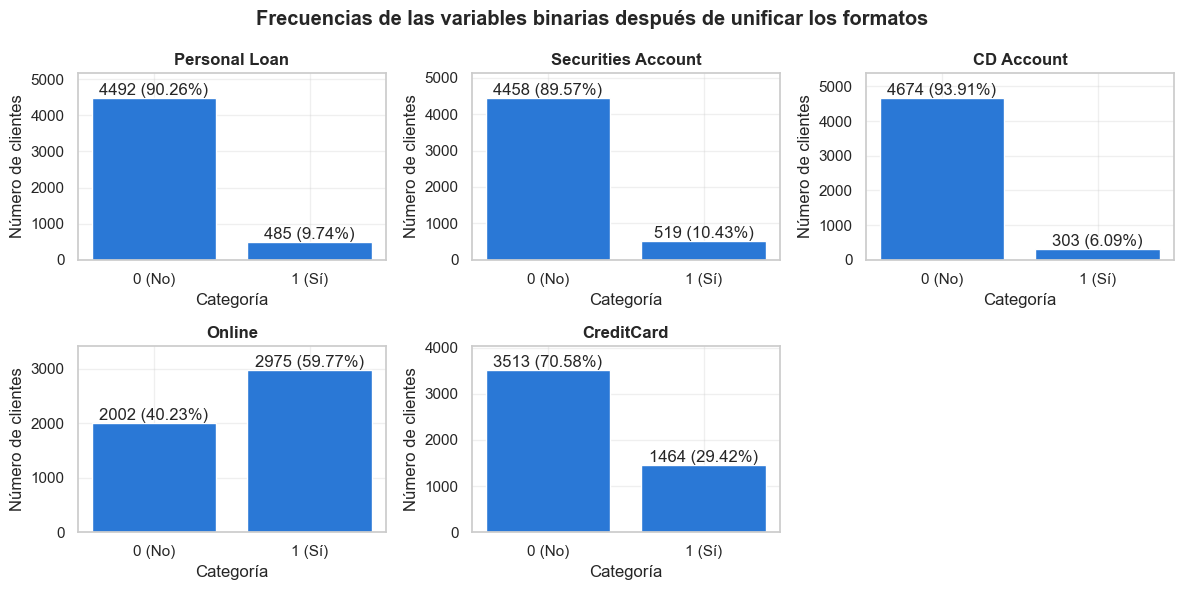

In [22]:
fig, ax = plt.subplots(figsize = (12, 6), nrows = 2, ncols = 3)
ax = ax.flatten()

for i, col in enumerate(catCols):
    counts_i = loan_df[col].value_counts()
    max_count = counts_i.values.max()
    sum_count = counts_i.values.sum()

    bars = ax[i].bar(counts_i.index, counts_i.values, color = COLOR_1)
    ax[i].grid(alpha = 0.3)
    ax[i].set_axisbelow(True)

    ax[i].set_xticks([0, 1], ['0 (No)', '1 (Sí)'])
    ax[i].set_title(col)
    ax[i].set_xlabel('Categoría')
    ax[i].set_ylabel('Número de clientes')
    ax[i].set_ylim([0, max_count * 1.15])

    for bar in bars:
        ax[i].text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{bar.get_height():.0f} ({100 * bar.get_height() / sum_count:.2f}%)', ha = 'center', va = 'bottom')

ax[-1].set_axis_off()

fig.suptitle('Frecuencias de las variables binarias después de unificar los formatos')
plt.tight_layout()
plt.show()

Después de la unificación las 5 variables solo contienen los valores 0 y 1, no se generaron valores nulos y pandas ya las reconoce como numéricas (`int64`). Se observa que la variable de salida `Personal Loan` está desbalanceada: menos del 10% de los clientes aceptó el préstamo.

4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [23]:
n_duplicados = loan_df.duplicated().sum()
print(f'Registros duplicados: {n_duplicados}')

Registros duplicados: 36


In [24]:
loan_df = loan_df.drop_duplicates()
loan_df = loan_df.reset_index().drop(columns = 'index')

print(f'Registros duplicados restantes: {loan_df.duplicated().sum()}')
print(f'Dimensiones del dataframe: {loan_df.shape}')
loan_df.tail()

Registros duplicados restantes: 0
Dimensiones del dataframe: (4941, 13)


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
4936,29,3,40,92697,1,1.9,3.0,0,0,0,0,1,0
4937,30,4,15,92037,4,0.4,1.0,85,0,0,0,1,0
4938,63,39,24,93023,2,0.3,3.0,0,0,0,0,0,0
4939,65,40,49,90034,3,0.5,2.0,0,0,0,0,1,0
4940,28,4,83,92612,3,0.8,1.0,0,0,0,0,1,1


**Respuesta:** se encontraron **36 registros duplicados** y se eliminaron, conservando la primera aparición de cada uno. El dataframe queda con **4941 registros** y el índice se reinició para que vaya de 0 a 4940 de forma continua.

5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [25]:
bin_cols = "Personal Loan, Securities Account, CD Account, Online, CreditCard".replace(', ', ',').split(',')

In [26]:
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype(object)
loan_df['Education'] = pd.Categorical(loan_df['Education'].astype(int), categories = [1, 2, 3], ordered = True)

for col in bin_cols:
    loan_df[col] = loan_df[col].astype('category')

loan_df.dtypes

Age                      int64
Experience               int64
Income                   int64
ZIP Code                object
Family                   int64
CCAvg                  float64
Education             category
Mortgage                 int64
Personal Loan         category
Securities Account    category
CD Account            category
Online                category
CreditCard            category
dtype: object

In [27]:
loan_df['Education'].cat.categories, loan_df['Education'].cat.ordered

(Index([1, 2, 3], dtype='int64'), True)

In [28]:
num_cols = loan_df.select_dtypes(include = ['int64', 'float64']).columns.tolist()
cat_cols = loan_df.select_dtypes(include = ['object', 'category']).columns.tolist()

print(f'Variables numéricas ({len(num_cols)}): {num_cols}')
print(f'Variables categóricas ({len(cat_cols)}): {cat_cols}')

Variables numéricas (6): ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
Variables categóricas (7): ['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [29]:
stats_num = loan_df[num_cols].describe().T
stats_num['skew'] = loan_df[num_cols].skew()
stats_num['kurt'] = loan_df[num_cols].kurt()

stats_num

,count,mean,std,min,25%,50%,75%,max,skew,kurt
Age,4941.0,45.560210,11.315617,24.0,36.0,46.0,55.0,67.0,-0.022754,-1.161599
Experience,4941.0,20.335357,11.308351,0.0,11.0,20.0,30.0,43.0,-0.015216,-1.134857
Income,4941.0,73.826553,46.106768,8.0,39.0,64.0,98.0,224.0,0.841991,-0.046164
Family,4941.0,2.391621,1.148244,1.0,1.0,2.0,3.0,4.0,0.159463,-1.403842
CCAvg,4941.0,1.935855,1.748406,0.0,0.7,1.5,2.6,10.0,1.594670,2.635545
Mortgage,4941.0,56.663631,101.875349,0.0,0.0,0.0,101.0,635.0,2.103865,4.760021


In [30]:
skewCols = loan_df[['Age', 'Income', 'Mortgage']].skew(axis = 0)
kurtCols = loan_df[['Age', 'Income', 'Mortgage']].kurt(axis = 0)

df_6 = pd.DataFrame(
    [skewCols.to_dict(), kurtCols.to_dict()],
    index = ['skew', 'kurt']
)

df_6

,Age,Income,Mortgage
skew,-0.022754,0.841991,2.103865
kurt,-1.161599,-0.046164,4.760021


**Respuesta:**

Pandas calcula la curtosis en exceso, por lo que una distribución normal tiene curtosis 0.

| Variable | Asimetría | Clasificación | Curtosis | Clasificación |
|---|---|---|---|---|
| `Age` | -0.02 | Aproximadamente simétrica | -1.16 | Platicúrtica |
| `Income` | 0.84 | Asimetría positiva moderada (sesgo a la derecha) | -0.05 | Aproximadamente mesocúrtica |
| `Mortgage` | 2.10 | Asimetría positiva fuerte (sesgo a la derecha) | 4.76 | Leptocúrtica |

* **`Age`:** la asimetría es prácticamente 0, así que la distribución es simétrica. La curtosis negativa indica una distribución más plana que la normal, con colas ligeras y sin un pico marcado.
* **`Income`:** la asimetría positiva indica una cola hacia la derecha: la mayoría de los clientes tiene ingresos bajos o medios y pocos tienen ingresos muy altos. La curtosis cercana a 0 indica colas similares a las de una normal.
* **`Mortgage`:** tiene la asimetría más alta. Los valores se concentran en el extremo izquierdo con una cola larga a la derecha. La curtosis alta indica un pico muy pronunciado y colas pesadas, es decir, presencia de valores extremos.

7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

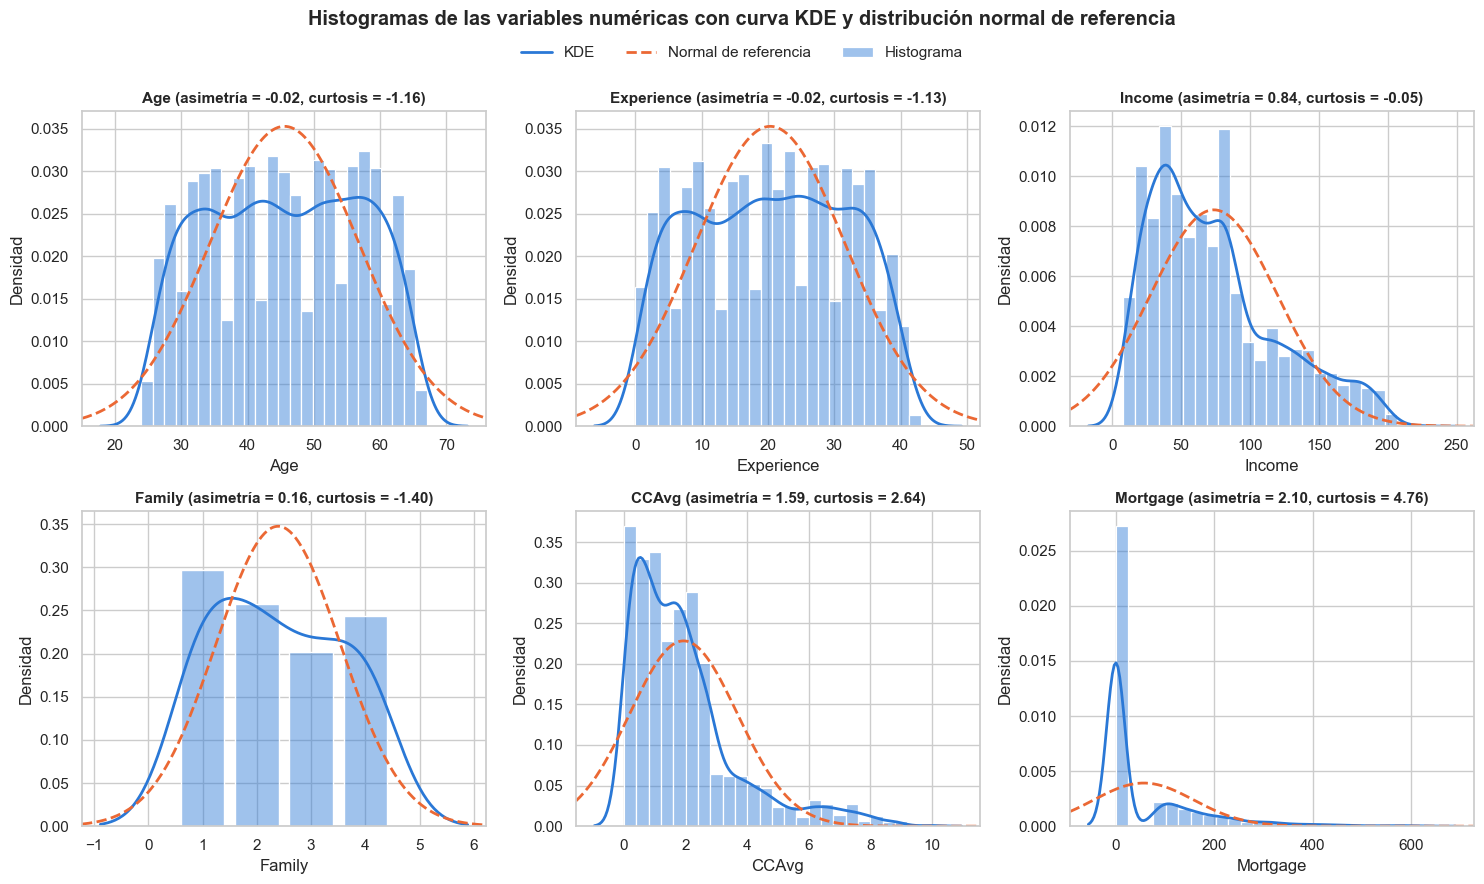

In [31]:
fig, ax = plt.subplots(figsize = (15, 9), nrows = 2, ncols = 3)
ax = ax.flatten()

for i, col in enumerate(num_cols):
    valuesCol = loan_df[col]

    # Histograma (Family es discreta, se usa una barra por valor)
    if col == 'Family':
        sns.histplot(valuesCol, stat = 'density', discrete = True, shrink = 0.8, color = COLOR_1, alpha = 0.45, ax = ax[i], label = 'Histograma')
    else:
        sns.histplot(valuesCol, stat = 'density', bins = 25, color = COLOR_1, alpha = 0.45, ax = ax[i], label = 'Histograma')

    # Curva KDE
    # (Family solo toma 4 valores, se suaviza más para que la curva no oscile)
    sns.kdeplot(valuesCol, color = COLOR_1, linewidth = 2, bw_adjust = 3 if col == 'Family' else 1, ax = ax[i], label = 'KDE')

    # Curva de una distribución normal con la misma media y desviación estándar
    mu, std = norm.fit(valuesCol)
    x_min, x_max = ax[i].get_xlim()
    x_array = np.linspace(x_min, x_max, 300)
    ax[i].plot(x_array, norm.pdf(x_array, loc = mu, scale = std), color = COLOR_2, linewidth = 2, linestyle = '--', label = 'Normal de referencia')
    ax[i].set_xlim([x_min, x_max])

    ax[i].set_title(f'{col} (asimetría = {valuesCol.skew():.2f}, curtosis = {valuesCol.kurt():.2f})', fontsize = 11)
    ax[i].set_xlabel(col)
    ax[i].set_ylabel('Densidad')

handles, labels = ax[0].get_legend_handles_labels()

fig.suptitle('Histogramas de las variables numéricas con curva KDE y distribución normal de referencia')
fig.legend(handles, labels, loc = 'upper center', bbox_to_anchor = (0.5, 0.955), ncol = 3, frameon = False)
plt.tight_layout(rect = [0, 0, 1, 0.95])
plt.show()

**Comparación de los histogramas con la asimetría y la curtosis:**

* **`Age`:** coincide con lo esperado. El histograma es simétrico alrededor de los 45 años y es más plano que la curva normal: las frecuencias son parecidas entre los 30 y los 60 años y caen de golpe en los extremos. Esto corresponde a una asimetría cercana a 0 y a una curtosis negativa (platicúrtica).
* **`Income`:** coincide con lo esperado. La mayor parte de los clientes se concentra entre 20 y 90 mil dólares y hay una cola hacia la derecha que llega a más de 200 mil. La curva KDE queda desplazada a la izquierda de la normal, lo que corresponde a la asimetría positiva de 0.84.
* **`Mortgage`:** coincide con lo esperado. Hay un pico muy alto en 0, porque el 69% de los clientes no tiene hipoteca, y una cola larga a la derecha que llega hasta 635. La distribución no se parece a la normal, lo que corresponde a una asimetría fuerte (2.10) y a una distribución leptocúrtica (4.76).

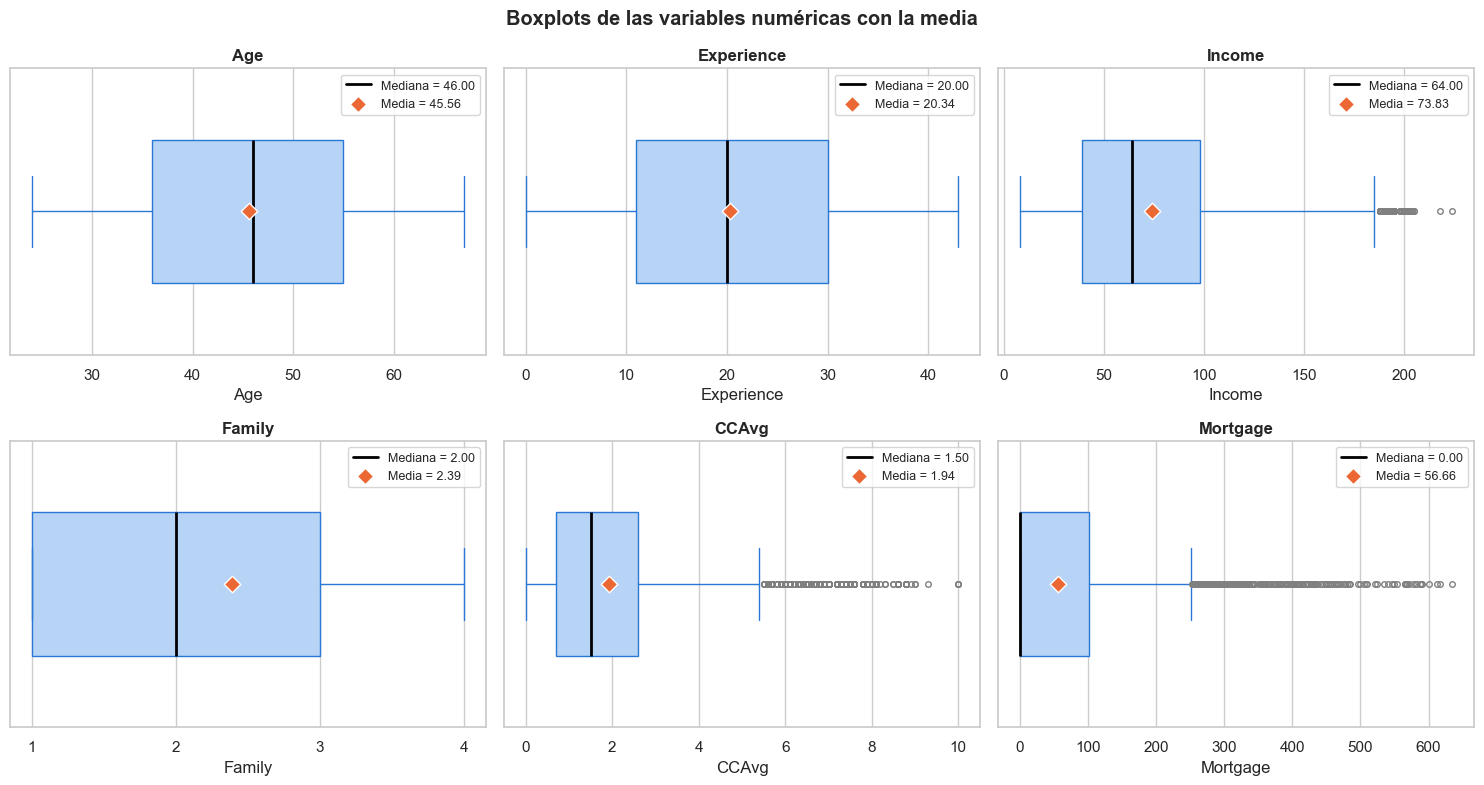

In [32]:
fig, ax = plt.subplots(figsize = (15, 8), nrows = 2, ncols = 3)
ax = ax.flatten()

for i, col in enumerate(num_cols):
    mean_i = loan_df[col].mean()
    median_i = loan_df[col].median()

    ax[i].boxplot(
        loan_df[col], vert = False, widths = 0.5, patch_artist = True,
        boxprops = dict(facecolor = '#b7d3f6', edgecolor = COLOR_1),
        whiskerprops = dict(color = COLOR_1), capprops = dict(color = COLOR_1),
        medianprops = dict(color = 'black', linewidth = 2),
        flierprops = dict(marker = 'o', markersize = 4, markerfacecolor = 'none', markeredgecolor = 'gray')
    )

    ax[i].plot([], [], color = 'black', linewidth = 2, label = f'Mediana = {median_i:.2f}')
    ax[i].scatter(mean_i, 1, marker = 'D', s = 70, color = COLOR_2, edgecolor = 'white', zorder = 3, label = f'Media = {mean_i:.2f}')

    ax[i].set_title(col)
    ax[i].set_xlabel(col)
    ax[i].set_yticks([])
    if col == 'Family':
        ax[i].set_xticks([1, 2, 3, 4])
    ax[i].legend(loc = 'upper right', fontsize = 9)

fig.suptitle('Boxplots de las variables numéricas con la media')
plt.tight_layout()
plt.show()

In [33]:
df_7 = pd.DataFrame({
    'media': loan_df[num_cols].mean(),
    'mediana': loan_df[num_cols].median(),
    'skew': loan_df[num_cols].skew()
})
df_7['media - mediana'] = df_7['media'] - df_7['mediana']

df_7.round(2)

,media,mediana,skew,media - mediana
Age,45.56,46.0,-0.02,-0.44
Experience,20.34,20.0,-0.02,0.34
Income,73.83,64.0,0.84,9.83
Family,2.39,2.0,0.16,0.39
CCAvg,1.94,1.5,1.59,0.44
Mortgage,56.66,0.0,2.10,56.66


**Respuesta:**

La posición de la media respecto a la mediana indica la dirección del sesgo. La media es sensible a los valores extremos y se desplaza hacia la cola de la distribución, mientras que la mediana no cambia.

* **Media aproximadamente igual a la mediana:** distribución simétrica. Es el caso de `Age` (45.56 contra 46) y `Experience` (20.34 contra 20), que tienen asimetría cercana a 0 y no presentan valores atípicos.
* **Media mayor que la mediana:** sesgo positivo (a la derecha). Es el caso de `Income` (73.83 contra 64), `CCAvg` (1.94 contra 1.5) y `Mortgage` (56.66 contra 0). En los tres boxplots la media queda a la derecha de la mediana y hay valores atípicos solo en el lado derecho. Entre mayor es la separación relativa, mayor es la asimetría: `Mortgage` es el caso extremo, porque su mediana es 0 y la media es arrastrada por los pocos clientes con hipotecas altas.
* **`Family`:** la media (2.39) es ligeramente mayor que la mediana (2), lo que coincide con una asimetría positiva pequeña (0.16). Al ser una variable discreta con solo 4 valores, el sesgo es poco relevante.

Ninguna variable tiene la media a la izquierda de la mediana de forma notable, por lo que no hay sesgos negativos importantes.

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [34]:
loan_df[cat_cols].astype(object).describe().T

,count,unique,top,freq
ZIP Code,4941,467,94720,163
Education,4941,3,1,2079
Personal Loan,4941,2,0,4462
Securities Account,4941,2,0,4426
CD Account,4941,2,0,4640
Online,4941,2,1,2951
CreditCard,4941,2,0,3489


In [35]:
print(f'Valores únicos de ZIP Code: {loan_df["ZIP Code"].nunique()}')

Valores únicos de ZIP Code: 467


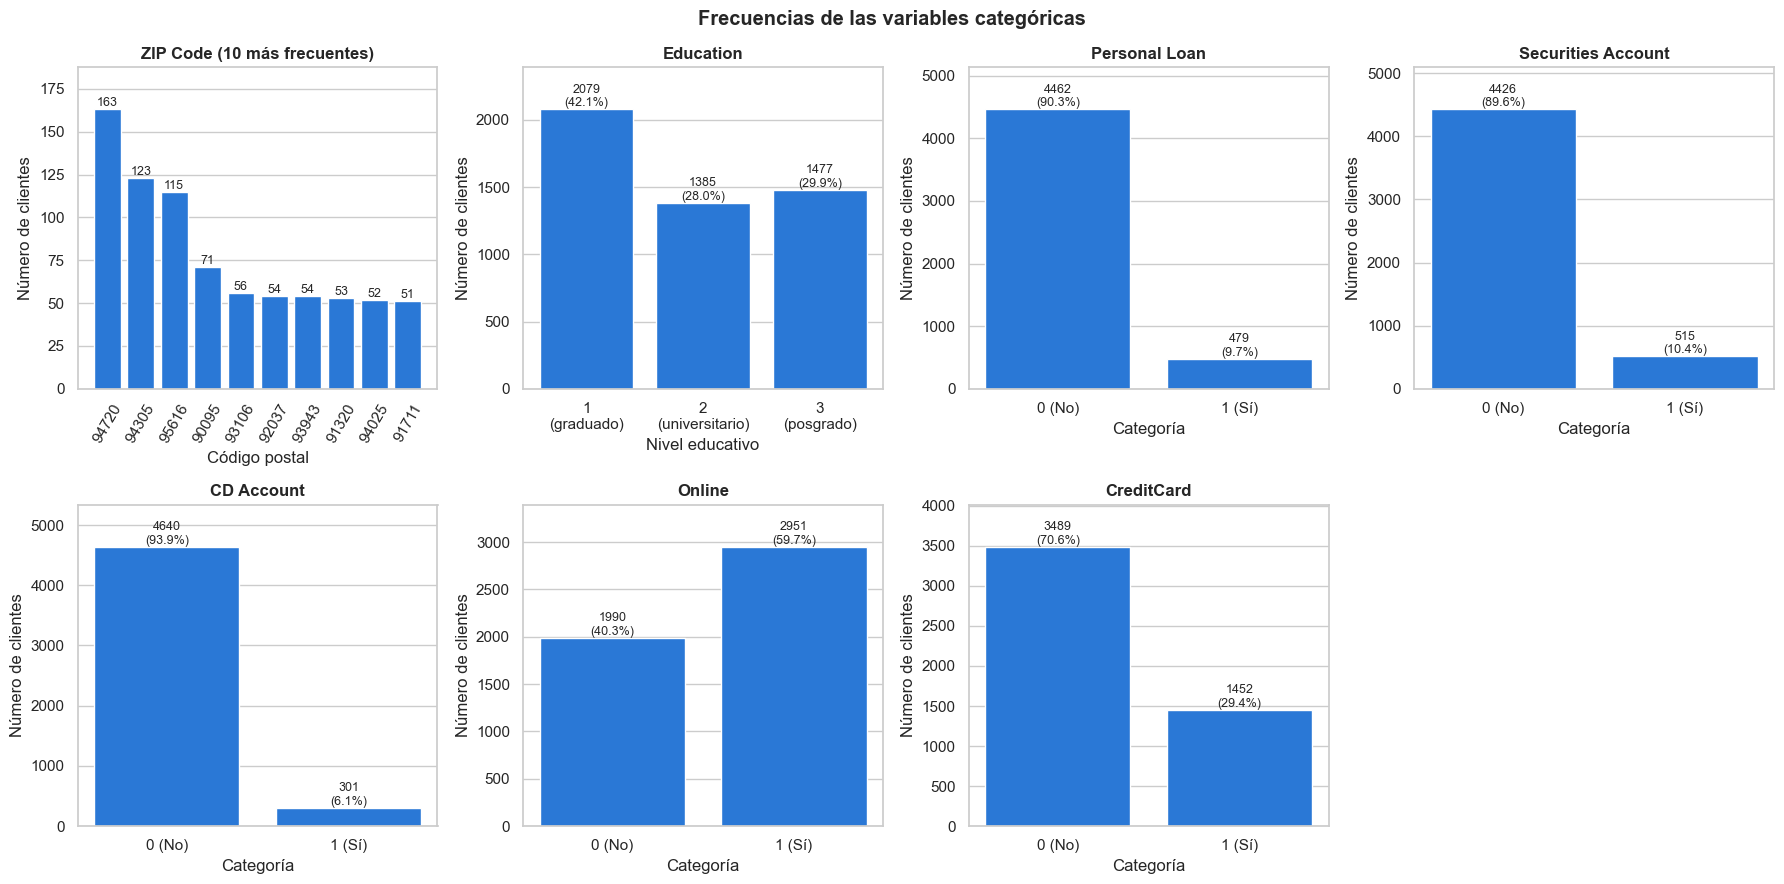

In [36]:
fig, ax = plt.subplots(figsize = (18, 9), nrows = 2, ncols = 4)
ax = ax.flatten()

n_total = loan_df.shape[0]

for i, col in enumerate(cat_cols):
    if col == 'ZIP Code':
        # Alta cardinalidad: solo los 10 códigos postales más frecuentes
        counts_i = loan_df[col].value_counts().head(10)
        labels_i = counts_i.index.astype(str)
        title_i = 'ZIP Code (10 más frecuentes)'
        xlabel_i = 'Código postal'
    elif col == 'Education':
        counts_i = loan_df[col].value_counts().sort_index()
        labels_i = ['1\n(graduado)', '2\n(universitario)', '3\n(posgrado)']
        title_i = col
        xlabel_i = 'Nivel educativo'
    else:
        counts_i = loan_df[col].value_counts().sort_index()
        labels_i = ['0 (No)', '1 (Sí)']
        title_i = col
        xlabel_i = 'Categoría'

    bars = ax[i].bar(labels_i, counts_i.values, color = COLOR_1)
    ax[i].grid(axis = 'x', visible = False)
    ax[i].set_axisbelow(True)

    ax[i].set_title(title_i)
    ax[i].set_xlabel(xlabel_i)
    ax[i].set_ylabel('Número de clientes')
    ax[i].set_ylim([0, counts_i.values.max() * 1.15])

    if col == 'ZIP Code':
        ax[i].tick_params(axis = 'x', rotation = 60)

    for bar in bars:
        if col == 'ZIP Code':
            text_i = f'{bar.get_height():.0f}'
        else:
            text_i = f'{bar.get_height():.0f}\n({100 * bar.get_height() / n_total:.1f}%)'
        ax[i].text(bar.get_x() + bar.get_width() / 2, bar.get_height(), text_i, ha = 'center', va = 'bottom', fontsize = 9)

ax[-1].set_axis_off()

fig.suptitle('Frecuencias de las variables categóricas')
plt.tight_layout()
plt.show()

**Observaciones:**

* **`ZIP Code`** tiene alta cardinalidad: 467 códigos postales distintos. El más frecuente es 94720 con 163 clientes, que es apenas el 3.3% del total, así que los clientes están muy repartidos.
* **`Education`:** el nivel más común es 1 (42.1%). Los niveles 2 (28.0%) y 3 (29.9%) tienen proporciones parecidas.
* **`Personal Loan`:** solo el 9.7% de los clientes aceptó el préstamo. La variable de salida está desbalanceada, lo cual se debe tomar en cuenta al construir el modelo.
* **`Securities Account`** y **`CD Account`:** la gran mayoría de los clientes no tiene estos productos (89.6% y 93.9%).
* **`Online`:** es la única variable binaria donde predomina el 1. El 59.7% usa la banca en línea.
* **`CreditCard`:** el 29.4% es titular de una tarjeta de crédito.

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

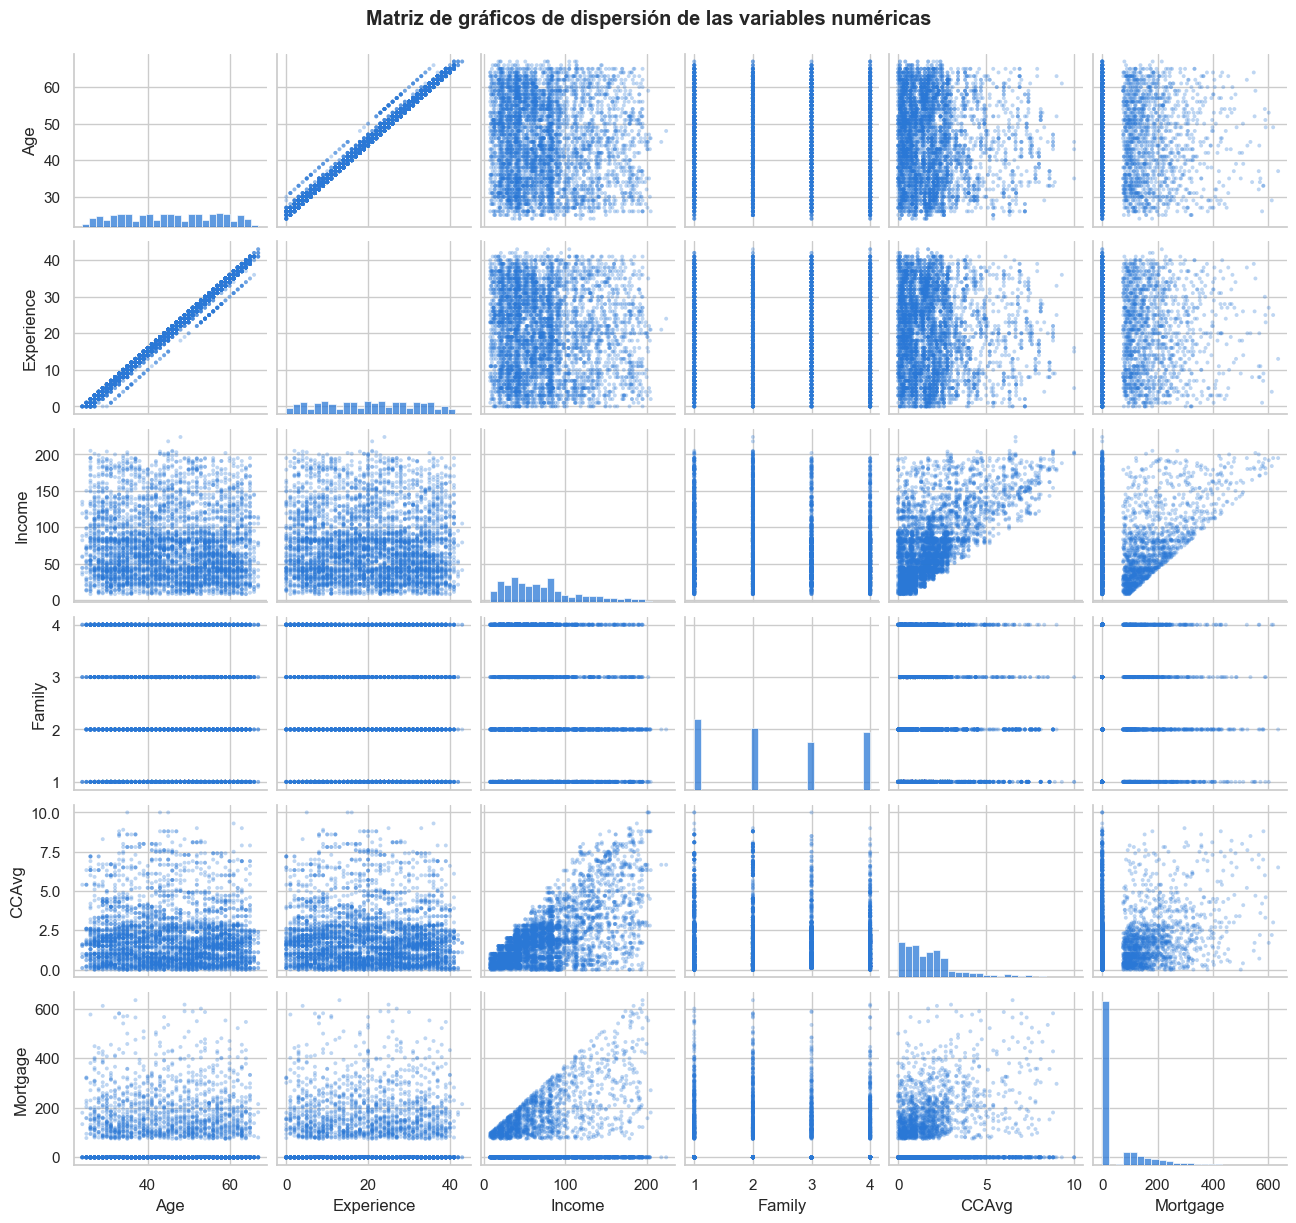

In [37]:
g = sns.pairplot(
    loan_df[num_cols], height = 2, aspect = 1.1,
    plot_kws = dict(s = 8, alpha = 0.3, color = COLOR_1, edgecolor = 'none'),
    diag_kws = dict(color = COLOR_1, bins = 25)
)

g.fig.suptitle('Matriz de gráficos de dispersión de las variables numéricas', y = 1.02, fontweight = 'bold')
plt.show()

**Par seleccionado: `Age` y `Experience`**

Es la relación más evidente de la matriz. Los puntos forman una línea recta ascendente muy estrecha: a mayor edad, mayor experiencia laboral, y casi no hay dispersión alrededor de la línea. Tiene sentido, porque la experiencia se acumula con los años y la mayoría de las personas empieza a trabajar a una edad similar. Se espera una correlación positiva muy cercana a 1.

Otros patrones que se observan:

* **`Income` y `CCAvg`:** relación positiva pero con mucha más dispersión. Los clientes con ingresos bajos tienen gastos bajos con tarjeta, y los gastos altos solo aparecen en clientes con ingresos altos, por lo que la nube tiene forma triangular.
* **`Income` y `Mortgage`:** relación positiva débil. Muchos puntos se alinean en `Mortgage` = 0, que corresponde a los clientes sin hipoteca.
* **`Family`:** al ser discreta forma franjas y no muestra una tendencia clara con ninguna variable.
* `Age` y `Experience` no muestran relación con el resto de las variables: las nubes de puntos son rectangulares.

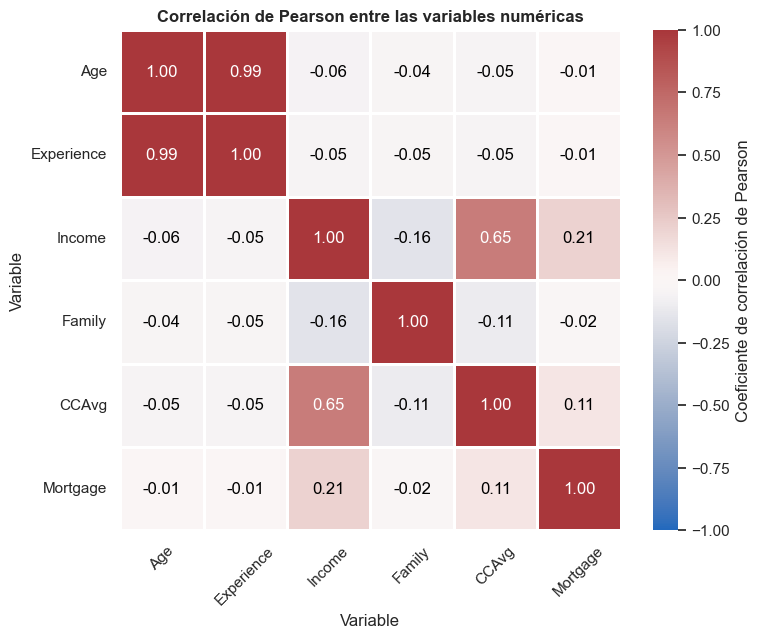

In [38]:
corr = loan_df[num_cols].corr(method = 'pearson')

fig, ax = plt.subplots(figsize = (8, 6.5))
sns.heatmap(
    corr, cmap = 'vlag', vmin = -1, vmax = 1, center = 0,
    square = True, linewidths = 1, linecolor = 'white',
    cbar_kws = dict(label = 'Coeficiente de correlación de Pearson'), ax = ax
)

# Valor de la correlación en cada celda
for r in range(corr.shape[0]):
    for c in range(corr.shape[1]):
        value = corr.iloc[r, c]
        ax.text(c + 0.5, r + 0.5, f'{value:.2f}', ha = 'center', va = 'center', color = 'white' if abs(value) > 0.6 else 'black')

ax.set_title('Correlación de Pearson entre las variables numéricas')
ax.set_xlabel('Variable')
ax.set_ylabel('Variable')
ax.tick_params(axis = 'x', rotation = 45)
ax.tick_params(axis = 'y', rotation = 0)

plt.tight_layout()
plt.show()

**Respuesta:**

Sí, el valor obtenido corresponde con lo esperado. La correlación de Pearson entre `Age` y `Experience` es **0.99**, es decir, una relación lineal positiva casi perfecta, igual que la línea recta que se observa en la matriz de dispersión. En la práctica ambas variables aportan casi la misma información, lo que se debe considerar al construir el modelo para evitar multicolinealidad.

El resto de los valores también coincide con lo observado:

* `Income` y `CCAvg` tienen una correlación positiva moderada de 0.65.
* `Income` y `Mortgage` tienen una correlación positiva débil de 0.21.
* Las demás correlaciones están entre -0.16 y 0.11, por lo que prácticamente no hay relación lineal entre esas variables.

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


**Variables numéricas**

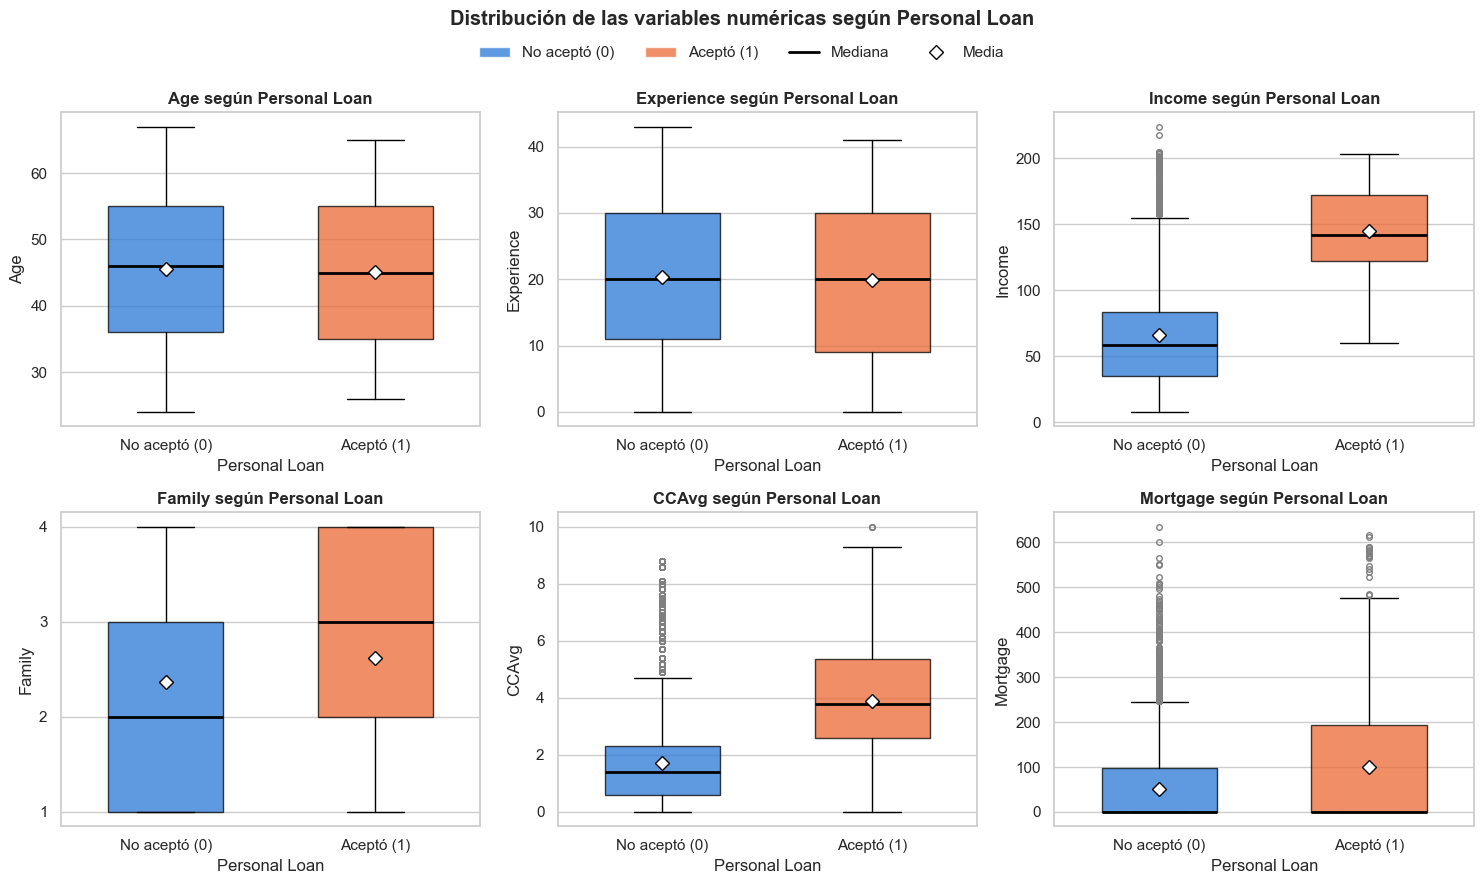

In [39]:
loan_labels = {0: 'No aceptó (0)', 1: 'Aceptó (1)'}
loan_colors = {0: COLOR_1, 1: COLOR_2}

fig, ax = plt.subplots(figsize = (15, 9), nrows = 2, ncols = 3)
ax = ax.flatten()

for i, col in enumerate(num_cols):
    data_i = [loan_df.loc[loan_df['Personal Loan'] == k, col] for k in [0, 1]]

    bp = ax[i].boxplot(
        data_i, widths = 0.55, patch_artist = True, showmeans = True,
        medianprops = dict(color = 'black', linewidth = 2),
        meanprops = dict(marker = 'D', markerfacecolor = 'white', markeredgecolor = 'black', markersize = 7),
        flierprops = dict(marker = 'o', markersize = 4, markerfacecolor = 'none', markeredgecolor = 'gray')
    )

    for patch, k in zip(bp['boxes'], [0, 1]):
        patch.set_facecolor(loan_colors[k])
        patch.set_alpha(0.75)

    ax[i].set_xticks([1, 2], [loan_labels[0], loan_labels[1]])
    ax[i].set_title(f'{col} según Personal Loan')
    ax[i].set_xlabel('Personal Loan')
    ax[i].set_ylabel(col)
    ax[i].grid(axis = 'x', visible = False)
    if col == 'Family':
        ax[i].set_yticks([1, 2, 3, 4])

legend_handles = [
    plt.Rectangle((0, 0), 1, 1, facecolor = loan_colors[0], alpha = 0.75, label = loan_labels[0]),
    plt.Rectangle((0, 0), 1, 1, facecolor = loan_colors[1], alpha = 0.75, label = loan_labels[1]),
    plt.Line2D([], [], color = 'black', linewidth = 2, label = 'Mediana'),
    plt.Line2D([], [], marker = 'D', linestyle = 'none', markerfacecolor = 'white', markeredgecolor = 'black', markersize = 7, label = 'Media')
]

fig.suptitle('Distribución de las variables numéricas según Personal Loan')
fig.legend(handles = legend_handles, loc = 'upper center', bbox_to_anchor = (0.5, 0.955), ncol = 4, frameon = False)
plt.tight_layout(rect = [0, 0, 1, 0.95])
plt.show()

In [40]:
loan_df.groupby('Personal Loan')[num_cols].agg(['mean', 'median']).round(2).T

Personal Loan          0       1
Age        mean    45.61   45.08
           median  46.00   45.00
Experience mean    20.39   19.86
           median  20.00   20.00
Income     mean    66.22  144.71
           median  59.00  142.00
Family     mean     2.37    2.62
           median   2.00    3.00
CCAvg      mean     1.72    3.90
           median   1.40    3.80
Mortgage   mean    51.90  101.06
           median   0.00    0.00

**Hallazgos en las variables numéricas:**

* **`Income` es la variable que mejor separa a los dos grupos.** Los clientes que aceptaron el préstamo tienen una mediana de ingreso de 142 mil dólares, contra 59 mil de quienes no lo aceptaron. Las cajas casi no se traslapan: el 75% de quienes aceptaron gana más que el 75% de quienes no aceptaron.
* **`CCAvg` muestra el mismo patrón.** Quienes aceptaron gastan en promedio 3.90 mil dólares al mes con tarjeta de crédito, más del doble que quienes no aceptaron (1.72).
* **`Mortgage`:** la mediana es 0 en ambos grupos, pero la media y la dispersión son mayores entre quienes aceptaron (101 contra 52).
* **`Family`:** quienes aceptaron tienden a tener familias más grandes (mediana de 3 contra 2).
* **`Age` y `Experience` no distinguen entre los grupos.** Las cajas son prácticamente idénticas, por lo que estas variables por sí solas aportan poco para predecir la aceptación del préstamo.

**Variables categóricas**

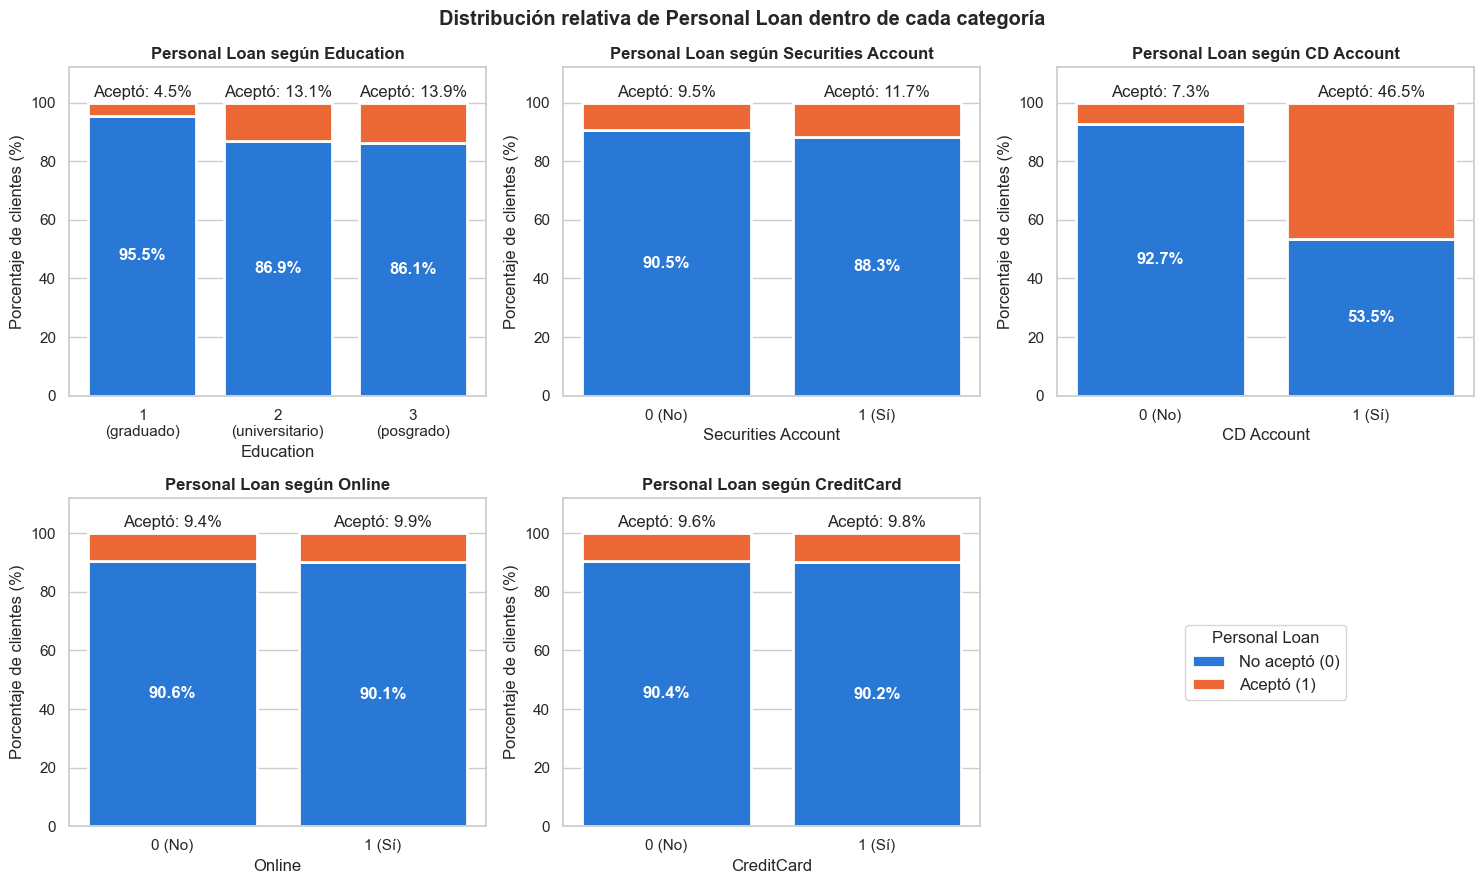

In [41]:
cat_cols_10 = [col for col in cat_cols if col not in ['ZIP Code', 'Personal Loan']]

fig, ax = plt.subplots(figsize = (15, 9), nrows = 2, ncols = 3)
ax = ax.flatten()

for i, col in enumerate(cat_cols_10):
    # Distribución relativa de Personal Loan dentro de cada categoría
    tab_i = pd.crosstab(loan_df[col], loan_df['Personal Loan'], normalize = 'index') * 100

    if col == 'Education':
        labels_i = ['1\n(graduado)', '2\n(universitario)', '3\n(posgrado)']
    else:
        labels_i = ['0 (No)', '1 (Sí)']

    ax[i].bar(labels_i, tab_i[0].values, color = loan_colors[0], edgecolor = 'white', linewidth = 2, label = loan_labels[0])
    bars = ax[i].bar(labels_i, tab_i[1].values, bottom = tab_i[0].values, color = loan_colors[1], edgecolor = 'white', linewidth = 2, label = loan_labels[1])

    for bar, pct_0, pct_1 in zip(bars, tab_i[0].values, tab_i[1].values):
        x_i = bar.get_x() + bar.get_width() / 2
        ax[i].text(x_i, pct_0 / 2, f'{pct_0:.1f}%', ha = 'center', va = 'center', color = 'white', fontweight = 'bold')
        ax[i].text(x_i, 101, f'Aceptó: {pct_1:.1f}%', ha = 'center', va = 'bottom')

    ax[i].set_title(f'Personal Loan según {col}')
    ax[i].set_xlabel(col)
    ax[i].set_ylabel('Porcentaje de clientes (%)')
    ax[i].set_ylim([0, 112])
    ax[i].set_yticks(range(0, 101, 20))
    ax[i].grid(axis = 'x', visible = False)
    ax[i].set_axisbelow(True)

handles, labels = ax[0].get_legend_handles_labels()
ax[-1].set_axis_off()
ax[-1].legend(handles, labels, title = 'Personal Loan', loc = 'center', fontsize = 12, title_fontsize = 12)

fig.suptitle('Distribución relativa de Personal Loan dentro de cada categoría')
plt.tight_layout()
plt.show()

**Hallazgos en las variables categóricas:**

* **`CD Account` es la variable categórica con mayor relación con la variable de salida.** El 46.5% de los clientes con cuenta de certificado de depósito aceptó el préstamo, contra solo el 7.3% de quienes no la tienen. Hay que considerar que solo el 6.1% de los clientes tiene este tipo de cuenta.
* **`Education`:** la aceptación es aproximadamente el triple en los niveles 2 (13.1%) y 3 (13.9%) que en el nivel 1 (4.5%). Un mayor nivel educativo se asocia con mayor aceptación del préstamo.
* **`Securities Account`:** la diferencia es pequeña (11.7% contra 9.5%).
* **`Online` y `CreditCard` no muestran relación con la variable de salida.** La proporción de aceptación es prácticamente la misma en ambas categorías (entre 9.4% y 9.9%).

---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/

---